In [9]:
!pip install joblib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
import pandas as pd
df = pd.read_csv("../data/english_transactions_500.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (500, 11)


,id,description,type,category,item,merchant,amount,currency,language,source,template_family
0,ENG-0001,Paid Uber 90 EGP for ride.,Expense,Transportation,ride,Uber,90,EGP,English,synthetic,9
1,ENG-0002,my internship transferred 3500 EGP to me for m...,Income,Salary,NaN,NaN,3500,EGP,English,synthetic,salary_2
2,ENG-0003,I was charged 50 EGP for bus ticket at the bus...,Expense,Transportation,bus ticket,NaN,50,EGP,English,synthetic,4
3,ENG-0004,Received 2250 EGP as salary from the company.,Income,Salary,NaN,NaN,2250,EGP,English,synthetic,salary_0
4,ENG-0005,My apartment rent payment of 7800 EGP came thr...,Income,Rental Income,apartment rent,my tenant,7800,EGP,English,synthetic,income_generated_4



Columns: ['id', 'description', 'type', 'category', 'item', 'merchant', 'amount', 'currency', 'language', 'source', 'template_family']


In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nTransaction types:")
print(df["type"].value_counts())

print("\nCategories:")
print(df["category"].value_counts())

print("\nDuplicate descriptions:")
print(df["description"].duplicated().sum())

Missing values:
id                   0
description          0
type                 0
category             0
item                50
merchant           200
amount               0
currency             0
language             0
source               0
template_family      0
dtype: int64

Transaction types:
type
Expense    250
Income     250
Name: count, dtype: int64

Categories:
category
Salary               50
Rental Income        50
Gifts                50
Business Income      50
Freelance            50
Bills & Utilities    32
Education            32
Transportation       31
Groceries            31
Entertainment        31
Food & Dining        31
Shopping             31
Healthcare           31
Name: count, dtype: int64

Duplicate descriptions:
0


In [5]:
# Remove invalid or duplicate descriptions
df = df.dropna(
    subset=["description", "type", "category"]
).copy()

df["description"] = df["description"].astype(str).str.strip()

df = df[df["description"] != ""]
df = df.drop_duplicates(subset=["description"])

X = df["description"]

# Stratify by category to preserve category distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    df["category"],
    test_size=0.2,
    random_state=42,
    stratify=df["category"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


In [6]:
category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        sublinear_tf=True
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

category_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


Test Accuracy: 0.9500

Classification Report:
                   precision    recall  f1-score   support

Bills & Utilities       1.00      1.00      1.00         7
  Business Income       1.00      0.90      0.95        10
        Education       0.88      1.00      0.93         7
    Entertainment       0.86      1.00      0.92         6
    Food & Dining       0.71      0.83      0.77         6
        Freelance       1.00      1.00      1.00        10
            Gifts       1.00      1.00      1.00        10
        Groceries       1.00      0.83      0.91         6
       Healthcare       1.00      0.83      0.91         6
    Rental Income       0.91      1.00      0.95        10
           Salary       1.00      1.00      1.00        10
         Shopping       1.00      1.00      1.00         6
   Transportation       1.00      0.83      0.91         6

         accuracy                           0.95       100
        macro avg       0.95      0.94      0.94       100
     wei

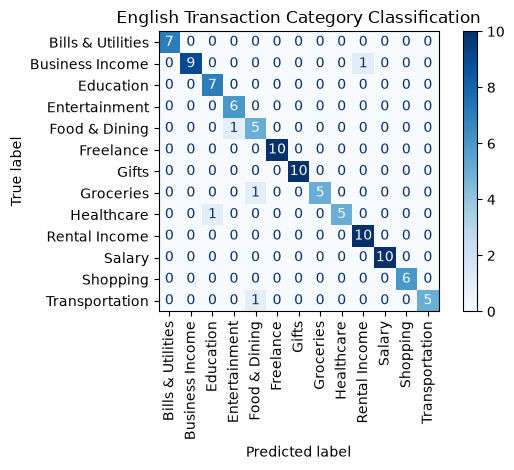

In [7]:
y_pred = category_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("English Transaction Category Classification")
plt.tight_layout()
plt.show()

In [8]:
examples = [
    "I bought shoes from Nike for 2000 EGP",
    "I received my monthly salary of 15000 EGP",
    "I paid 250 EGP for an Uber ride",
    "I purchased groceries from Carrefour for 800 EGP",
    "I earned 3000 EGP from a freelance project"
]

predictions = category_model.predict(examples)

for text, prediction in zip(examples, predictions):
    print(f"Input: {text}")
    print(f"Predicted category: {prediction}")
    print("-" * 50)

Input: I bought shoes from Nike for 2000 EGP
Predicted category: Shopping
--------------------------------------------------
Input: I received my monthly salary of 15000 EGP
Predicted category: Salary
--------------------------------------------------
Input: I paid 250 EGP for an Uber ride
Predicted category: Transportation
--------------------------------------------------
Input: I purchased groceries from Carrefour for 800 EGP
Predicted category: Groceries
--------------------------------------------------
Input: I earned 3000 EGP from a freelance project
Predicted category: Freelance
--------------------------------------------------
